# Value Function Iteration

**Seong Cho** · ACME Volume 2, Lab 18

**Lab objective:** learn how to solve sequential decision making problems, also known as dynamic optimization problems, by solving the finite-horizon cake eating problem.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import itertools
from unittest import mock
import numpy as np
import matplotlib.pyplot as plt

Dynamic optimization answers different questions than the optimization techniques studied so far. An oil company that considers each day in isolation would maximize excavation every day, but oil prices change with supply, so maximizing excavation may in fact lead to less profit. If the company considers how production on one day affects later decisions, it may do better.

## The Cake Eating Problem

Given a cake of a certain size, how do we eat it to maximize our enjoyment (*utility*) over time? These preferences are expressed with a smooth, strictly increasing and concave utility function $u$: given a cake of size $W$ and some amount of consumption $c_0 \in [0, W]$, the utility gained is $u(c_0)$. This lab restricts attention to utility functions with $u(0) = 0$, assumes $W = 1$, and cuts $W$ into $N$ equally-sized pieces. To maximize utility in one time period we consume the entire cake. How do we maximize utility over several days?

### Discount Factors

A person or firm typically has a time preference for saving or consuming: a dollar today can be invested and yield interest, whereas a dollar received next year does not include the accrued interest. Here, cake in the present yields more utility than cake in the future, modelled by multiplying future utility by a *discount factor* $\beta \in (0, 1)$. If we consume $c_0$ cake at time 0 and $c_1 = c_0$ cake at time 1, then

$$u(c_0) > \beta u(c_0).$$

### The Optimization Problem

Consuming a cake of size $W$ over $T + 1$ time periods is represented by a *policy vector* $[c_0, c_1, \ldots, c_T]^\mathsf{T}$ with $\sum_{i=0}^T c_i = W$. The optimization problem is

$$\max_{c_t} \sum_{t=0}^T \beta^t u(c_t) \quad \text{subject to} \quad \sum_{t=0}^T c_t = W, \quad c_t \ge 0.$$

## Problem 1: Graphing a policy

> **Problem 1.** Write a function called `graph_policy()` that will accept a policy vector $c$, a utility function $u(x)$, and a discount factor $\beta$. Return the total utility gained with the policy input. Also display a plot of the total cumulative utility gained over time. Ensure that the policy that the user passes in sums to 1. Otherwise, raise a `ValueError`. It might seem obvious what sort of policy will yield the most utility, but the truth may surprise you. See Figure 18.1 for some examples.
>
> ```python
> # The policy functions used in the Figure below.
> >>> pol1 = np.array([1, 0, 0, 0, 0])
> >>> pol2 = np.array([0, 0, 0, 0, 1])
> >>> pol3 = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
> >>> pol4 = np.array([.4, .3, .2, .1, 0])
> ```

Figure 18.1 plots these policies with $u(x) = \sqrt{x}$ and $\beta = 0.9$, with utilities 1.0, 0.6, 1.8 and 1.7. Policy 1 eats all of the cake in the first step and policy 2 all of it in the last step; their difference shows the effect of the discount factor on waiting to eat. Policy 3 eats the same amount at each step, and policy 4 starts with a lot and eats less and less until the cake runs out.

In [2]:
def graph_policy(policy, b, u):
    """Plot the utility gained over time.
    Return the total utility gained with the policy given.

    Parameters:
        policy (ndarray): Policy vector.
        b (float): Discount factor. 0 < beta < 1.
        u (function): Utility function.

    Returns:
        total_utility (float): Total utility gained from the policy given.
    """
    # Fixed: the spec asks for a ValueError when the policy does not sum to 1
    # (the grader's "Failed to raise a ValueError").
    if not np.isclose(np.sum(policy), 1):
        raise ValueError("The policy must sum to 1.")
    value = np.array([b**t*u(c) for t,c in enumerate(policy)])
    value_sum = np.array([sum(value[:i+1]) for i in range(len(policy))])
    domain = np.linspace(0, len(policy)-1, len(policy))
    print(domain)
    # Fixed: the label showed the discount factor b as the utility.
    plt.plot(domain, value_sum, label="Policy, Utility="+str(round(value_sum[-1], 3)))
    plt.legend()
    plt.show()
    # Fixed: was value_sum, the whole cumulative array; the spec (and the
    # docstring) ask for the total utility, its last entry.
    return value_sum[-1]

The four policies of Figure 18.1. `graph_policy()` calls `plt.show()` itself, so to overlay all four on one set of axes as in the figure, `plt.show()` is held back until the last call. The totals are checked against a direct computation of $\sum_t \beta^t \sqrt{c_t}$, and a policy that does not sum to 1 raises the `ValueError`.

[0. 1. 2. 3. 4.]
[0. 1. 2. 3. 4.]
[0. 1. 2. 3. 4.]
[0. 1. 2. 3. 4.]


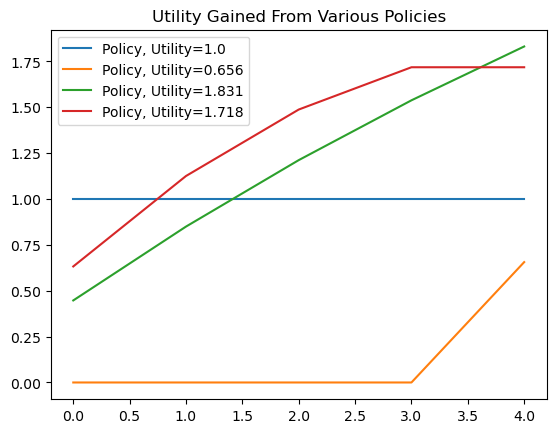

Policy 1: utility = 1.0000
Policy 2: utility = 0.6561
Policy 3: utility = 1.8314
Policy 4: utility = 1.7182
ValueError: The policy must sum to 1.


In [3]:
pol1 = np.array([1, 0, 0, 0, 0])
pol2 = np.array([0, 0, 0, 0, 1])
pol3 = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
pol4 = np.array([.4, .3, .2, .1, 0])
b = 0.9
u = lambda x: np.sqrt(x)

totals = []
with mock.patch.object(plt, "show"):
    for pol in [pol1, pol2, pol3, pol4]:
        totals.append(graph_policy(pol, b, u))
plt.title("Utility Gained From Various Policies")
plt.show()

for k, (pol, total) in enumerate(zip([pol1, pol2, pol3, pol4], totals), 1):
    print(f"Policy {k}: utility = {total:.4f}")
    assert np.isclose(total, sum(b**t * np.sqrt(c) for t, c in enumerate(pol)))
assert np.allclose(np.floor(np.array(totals)*10)/10, [1.0, 0.6, 1.8, 1.7])   # Figure 18.1's labels, truncated to one decimal.

try:
    graph_policy(np.array([.5, .4]), b, u)
except ValueError as e:
    print("ValueError:", e)
else:
    raise AssertionError("no ValueError")

Figure 18.1 labels the utilities truncated to one decimal place (policy 2 is worth $\beta^4 = 0.6561$ but shows as 0.6). Eating everything at once (policy 1) beats waiting until the end (policy 2), but spreading the cake out evenly (policy 3) beats both.

## The Value Function

The *value function* $V(a, b, W)$ is the highest utility we can achieve from time $a$ to time $b$:

$$V(a, b, W) = \max_{c_t} \sum_{t=a}^b \beta^t u(c_t) \quad \text{subject to} \quad \sum_{t=a}^b c_t = W, \quad c_t \ge 0.$$

For example, $V(a, b, \frac{W}{2})$ gives how much utility we will gain by proceeding optimally from $t = a$ if half of a cake of size $W$ was eaten before time $t = a$.

By using the optimal value in the future we can determine the optimal value for the present, so we iterate backwards. Let $W_i$ be the total amount of cake left at time $t = i$; then $W_{i+1} \le W_i$ for all $i$, because cake cannot be created. The value function can be expressed as

$$V(t, T, W_t) = \max_{W_{t+1}} \big(u(W_t - W_{t+1}) + \beta V(t, T-1, W_{t+1})\big). \tag{18.1}$$

$u(W_t - W_{t+1})$ is the value gained from eating $W_t - W_{t+1}$ cake, and $\beta V(t, T-1, W_{t+1})$ is the value of saving $W_{t+1}$ cake until later. Since $W$ is split into $N$ equally-sized pieces, $W_t$ has only $N + 1$ possible values, so $V(t, T, W_t)$ can be solved by trying each possible $W_{t+1}$ and choosing the one that gives the highest utility.

## Problem 2: The consumption matrix

> **Problem 2.** Write a helper function to assist in solving the value function. Assume our cake has volume 1 and $N$ equally-sized pieces. Write a method that accepts $N$ and a utility function $u(x)$. Create a partition vector whose entries correspond to possible amounts of cake. For example, if split a cake into 4 pieces, the vector is
>
> $$\mathbf{w} = [0, 0.25, 0.5, 0.75, 1.0]^\mathsf{T}.$$
>
> Construct and return a matrix whose $(ij)$th entry is the amount of utility gained by starting with $i$ pieces and saving $j$ pieces (where $i$ and $j$ start at 0). In other words, the $(ij)$th entry should be $u(w_i - w_j)$.
>
> Set impossible situations to 0 (i.e., eating more cake than you have available). The resulting lower triangular matrix is the *consumption matrix*.
>
> For example, the following matrix results with $N = 4$ and $u(x) = \sqrt{x}$.
>
> $$\begin{bmatrix} 0 & 0 & 0 & 0 & 0 \\ u(0.25) & 0 & 0 & 0 & 0 \\ u(0.5) & u(0.25) & 0 & 0 & 0 \\ u(0.75) & u(0.5) & u(0.25) & 0 & 0 \\ u(1) & u(0.75) & u(0.5) & u(0.25) & 0 \end{bmatrix}.$$

In [4]:
def consumption(N, u=np.sqrt):
    """Create the consumption matrix for the given parameters.

    Parameters:
        N (int): Number of pieces given, where each piece of cake is the
            same size.
        u (function): Utility function.

    Returns:
        C ((N+1,N+1) ndarray): Consumption matrix.
    """
    W = np.linspace(0, 1, N+1)
    M = np.zeros((N+1,N+1))
    for i in range(N+1):
        for j in range(N+1):
            if W[i]-W[j] >= 0:
                M[i,j] += u(W[i]-W[j])
    return M

In [5]:
C = consumption(4)
print(C)
u = np.sqrt
expected = np.array([[0,       0,       0,       0,       0],
                     [u(0.25), 0,       0,       0,       0],
                     [u(0.5),  u(0.25), 0,       0,       0],
                     [u(0.75), u(0.5),  u(0.25), 0,       0],
                     [u(1),    u(0.75), u(0.5),  u(0.25), 0]])
assert np.allclose(C, expected)

# A different utility function and size: entry (i, j) is u((i - j)/N) on and below the diagonal.
N, u3 = 7, lambda x: np.log(1 + x)
i, j = np.indices((N+1, N+1))
assert np.allclose(consumption(N, u3), np.where(i >= j, u3(np.maximum(i - j, 0)/N), 0))

[[0.         0.         0.         0.         0.        ]
 [0.5        0.         0.         0.         0.        ]
 [0.70710678 0.5        0.         0.         0.        ]
 [0.8660254  0.70710678 0.5        0.         0.        ]
 [1.         0.8660254  0.70710678 0.5        0.        ]]


## Solving the Optimization Problem

At each time $t$, $W_t$ can only take the $N + 1$ values $w_i = \frac{i}{N}$, which is $i$ pieces of cake remaining (for $N = 4$, $w_3 = 0.75$). The $(N+1) \times (T+1)$ *value function matrix* $A$ is calculated step by step: $A_{ij}$ is the value of having $w_i$ cake at time $j$, with $i$ and $j$ starting at 0. Note $A_{0j} = 0$, since $u(w_0) = u(0) = 0$.

Instead of asking how much cake to eat at some time $t$, we ask how valuable $w_i$ cake is at time $t$. At the last time period the only decision is obvious: eat the rest of the cake, since there is no value in having cake left over. Written in the form of (18.1),

$$A_{iT} = V(0, 0, w_i) = \max_{w_j} \big(u(w_i - w_j) + \beta V(0, -1, w_j)\big) = u(w_i), \tag{18.2}$$

because $V(0, -1, w_j) = 0$, so the maximum is at $w_j = 0$.

> **Achtung!** Given a time interval from $t = 0$ to $t = T$, the true utility of waiting until time $T$ to eat $w_i$ cake is actually $\beta^T u(W_i)$, as the difference of policies 1 and 2 in Figure 18.1 shows. However, programmatically the problem is solved backwards by beginning with $t = T$ as an isolated state and calculating its value. This is why the value function above is $V(0, 0, W_i)$ and not $V(T, T, W_i)$. After calculating $t = T$, $t = T - 1$ is introduced, and its value is calculated by considering the utility from eating $w_i - w_j$ cake at time $t = T - 1$, plus the utility of $\beta$ times the value of $w_j$ at time $T$. We then proceed iteratively backwards, considering $t = T - 2$ and considering its utility plus the utility of $\beta$ times the value at time $T - 1$.

## Problem 3: The last column of $A$

> **Problem 3.** Write a function called `eat_cake()` that accepts the stopping time $T$, the number of equal sized pieces that divides the cake $N$, a discount factor $\beta$, and a utility function $u(x)$. Return the value function matrix with all zeros except for the last column. The spec file indicates returning a policy matrix as well, for now return a matrix of zeros.
>
> For example, the following matrix results with $T = 3$, $N = 4$, $\beta = 0.9$, and $u(x) = \sqrt{x}$.
>
> $$\begin{bmatrix} 0 & 0 & 0 & u(0) \\ 0 & 0 & 0 & u(0.25) \\ 0 & 0 & 0 & u(0.5) \\ 0 & 0 & 0 & u(0.75) \\ 0 & 0 & 0 & u(1) \end{bmatrix}.$$

The function below is my finished `eat_cake()` for Problems 3 to 5: it fills in the whole value function matrix and the policy matrix. Its last columns are the Problem 3 starting point.

In [6]:
def eat_cake(T, N, B, u=np.sqrt):
    """Create the value and policy matrices for the given parameters.

    Parameters:
        T (int): Time at which to end (T+1 intervals).
        N (int): Number of pieces given, where each piece of cake is the
            same size.
        B (float): Discount factor, where 0 < B < 1.
        u (function): Utility function.

    Returns:
        A ((N+1,T+1) ndarray): The matrix where the (ij)th entry is the
            value of having w_i cake at time j.
        P ((N+1,T+1) ndarray): The matrix where the (ij)th entry is the
            number of pieces to consume given i pieces at time j.
    """
    A = np.zeros((N+1, T+1))
    A[:,-1] = np.array([u(i/N) for i in range(N+1)])
    P = np.zeros((N+1,T+1))
    P[:,-1] = np.array([i/N for i in range(N+1)])
    for i in range(T):
        CV = consumption(N, u=u)
        for j in range(N+1):
            # Fixed: was b*A[...], the global discount factor from the test
            # code at the bottom of the .py file, not the argument B.
            CV[:,j] += B*A[j,-(1+i)]
            CV[:,j][:j] = 0
        P[:,-(2+i)] = P[:,-1] - P[:,-1][np.argmax(CV, axis=1)]
        A[:,-(2+i)] = np.max(CV, axis=1)
    return A, P

In [7]:
A, P = eat_cake(3, 4, 0.9)
print(A[:, -1])
assert np.allclose(A[:, -1], np.sqrt([0, 0.25, 0.5, 0.75, 1]))   # u(w_i)
assert np.allclose(P[:, -1], [0, 0.25, 0.5, 0.75, 1])            # eat everything at time T

[0.         0.5        0.70710678 0.8660254  1.        ]


The next column of $A$ comes from modifying (18.2):

$$A_{i(T-1)} = V(0, 1, w_i) = \max_{w_j} \big(u(w_i - w_j) + \beta V(0, 0, w_j)\big) = \max_{w_j} \big(u(w_i - w_j) + \beta A_{jT}\big). \tag{18.3}$$

Only options with $w_j \le w_i$ count. Instead of doing these one by one for each $w_i$, compute them all at once in the $(N+1) \times (N+1)$ *current value matrix* $CV^t$, whose $(ij)$th entry is the value of eating $i - j$ pieces of cake at time $t$ and saving $j$ pieces until the next period. For $t = T - 1$,

$$CV^{T-1}_{ij} = u(w_i - w_j) + \beta A_{jT}. \tag{18.4}$$

The largest entry in the $i$th row of $CV^{T-1}$ is the optimal value at $T - 1$ given that we start with $w_i$ cake, and these row maxima become the column of $A$ for time $T - 1$. Since the last column of $A$ is known, we can iterate backwards to fill in the rest.

> **Achtung!** The notation $CV^t$ does not mean raising the matrix to the $t$th power, it indicates what time period we are in. All of the $CV^t$ could be grouped together into a three-dimensional matrix, $CV$, that has dimensions $(N+1) \times (N+1) \times (T+1)$. Although this is possible, we will not use $CV$ in this lab, and will instead only consider $CV^t$ for any given time $t$.

The spec's $CV^2$ for $T = 3$, $\beta = 0.9$, $N = 4$, $u(x) = \sqrt{x}$ (impossible entries set to 0), built from the consumption matrix and the last column of $A$. Each row maximum goes into column $t = 2$ of $A$.

In [8]:
CV2 = np.tril(consumption(4) + 0.9*A[:, 3])      # (18.4): entry (i, j) is u(w_i - w_j) + beta*A_j3 for j <= i
print(np.round(CV2, 3))
spec_CV2 = np.array([[0,     0,     0,     0,     0  ],
                     [0.5,   0.45,  0,     0,     0  ],
                     [0.707, 0.95,  0.636, 0,     0  ],
                     [0.866, 1.157, 1.136, 0.779, 0  ],
                     [1,     1.316, 1.343, 1.279, 0.9]])
assert np.allclose(CV2, spec_CV2, atol=5e-4)
print("row maxima:", CV2.max(axis=1))
assert np.allclose(CV2.max(axis=1), A[:, 2])

[[0.    0.    0.    0.    0.   ]
 [0.5   0.45  0.    0.    0.   ]
 [0.707 0.95  0.636 0.    0.   ]
 [0.866 1.157 1.136 0.779 0.   ]
 [1.    1.316 1.344 1.279 0.9  ]]
row maxima: [0.         0.5        0.95       1.15710678 1.34350288]


Repeating the process for $T - 2$ and so on fills in every column of $A$. In summary, at each time step $t$ find $CV^t$ and set $A_{it}$ as the maximum value of the $i$th row of $CV^t$:

$$CV^t_{ij} = u(w_i - w_j) + \beta A_{j(t+1)}, \qquad A_{it} = \max_j \big(CV^t_{ij}\big). \tag{18.5}$$

Figure 18.2 gives the value function matrix for $T = 3$, $\beta = 0.9$, $N = 4$ and $u(x) = \sqrt{x}$; its bottom left entry says the highest utility that can be achieved is 1.7195:

$$A = \begin{bmatrix} 0 & 0 & 0 & 0 \\ 0.5 & 0.5 & 0.5 & 0.5 \\ 0.95 & 0.95 & 0.95 & 0.707 \\ 1.355 & 1.355 & 1.157 & 0.866 \\ 1.7195 & 1.562 & 1.343 & 1 \end{bmatrix}.$$

## Problem 4: The value function matrix

> **Problem 4.** Complete the function `eat_cake()` to determine the entire value function matrix. Starting from the next to last column, iterate backwards by
> - calculating the current value matrix for time $t$ using (18.5),
> - finding the largest value in each row of the current value matrix,
> - filling in the corresponding column of $A$ with these values.

`eat_cake()` above already does this. The check compares it with Figure 18.2 and with a brute-force reference: $A_{ij}$ is the best total utility from $i$ pieces over the $T - j + 1$ periods $j, \ldots, T$ (discounting from time $j$), found by trying every way of splitting the $i$ pieces among those periods.

In [9]:
def brute_value(i, periods, B, u, N):
    # Best sum_t B^t u(k_t/N) over all ways of eating exactly i pieces in the given number of periods.
    return max(sum(B**t * u(k/N) for t, k in enumerate(ks))
               for ks in itertools.product(range(i+1), repeat=periods) if sum(ks) == i)

def brute_A(T, N, B, u):
    return np.array([[brute_value(i, T-j+1, B, u, N) for j in range(T+1)] for i in range(N+1)])

A, P = eat_cake(3, 4, 0.9)
print(A)
spec_A = np.array([[0,      0,     0,     0    ],
                   [0.5,    0.5,   0.5,   0.5  ],
                   [0.95,   0.95,  0.95,  0.707],
                   [1.355,  1.355, 1.157, 0.866],
                   [1.7195, 1.562, 1.343, 1    ]])
assert np.allclose(A, spec_A, atol=5e-4)
assert np.allclose(A, brute_A(3, 4, 0.9, np.sqrt))

# Other sizes, discount factors and utility functions.
utilities = {"sqrt": np.sqrt, "log(1+x)": np.log1p, "x^0.3": lambda x: x**0.3}
for (T, N, B), (name, uf) in itertools.product([(2, 6, 0.5), (4, 5, 0.95), (5, 4, 0.8)], utilities.items()):
    assert np.allclose(eat_cake(T, N, B, uf)[0], brute_A(T, N, B, uf)), (T, N, B, name)
print("eat_cake() value matrices match the brute-force reference.")

[[0.         0.         0.         0.        ]
 [0.5        0.5        0.5        0.5       ]
 [0.95       0.95       0.95       0.70710678]
 [1.355      1.355      1.15710678 0.8660254 ]
 [1.7195     1.56210678 1.34350288 1.        ]]
eat_cake() value matrices match the brute-force reference.


## The Policy Matrix

The value function matrix contains the maximum possible utility, but it does not show directly which policy to follow. The $(N+1) \times (T+1)$ *policy matrix* $P$ does: its $(ij)$th entry is how much cake to eat at time $j$ if we have $i$ pieces of cake. The last column is $P_{iT} = w_i$, because at time $T$ the remainder of the cake should be eaten. For earlier times, take $w_i - w_j$ where $j$ is the smallest index of the maximum value in row $i$ of $CV^t$:

$$P_{it} = w_i - w_j, \qquad j = \big\{\min\{j\} \;\big|\; CV^t_{ij} \ge CV^t_{ik} \;\; \forall k \in [0, 1, \ldots, N]\big\}.$$

For $T = 3$, $\beta = 0.9$, $N = 4$, $u(x) = \sqrt{x}$,

$$P = \begin{bmatrix} 0 & 0 & 0 & 0 \\ 0.25 & 0.25 & 0.25 & 0.25 \\ 0.25 & 0.25 & 0.25 & 0.5 \\ 0.25 & 0.25 & 0.5 & 0.75 \\ 0.25 & 0.5 & 0.5 & 1 \end{bmatrix}.$$

The optimal policy is found by starting at $i = N$, $j = 0$ and eating as much cake as the $(ij)$th entry indicates, then moving to the row of the cake that is left and the next column. In the spec's figure, red arrows trace this path from column 0 and blue arrows the path from column 2 (only 2 time intervals); it asks: what would be the optimal policy if we had 3 time intervals? The non-simplified version of Figure 18.2 shows that $A_{ij}$ is the value of following the optimal path from $P_{ij}$:

$$A = \begin{bmatrix}
0 & 0 & 0 & 0 \\
\sqrt{0.25} & \sqrt{0.25} & \sqrt{0.25} & \sqrt{0.25} \\
\sqrt{0.25} + \beta\sqrt{0.25} & \sqrt{0.25} + \beta\sqrt{0.25} & \sqrt{0.25} + \beta\sqrt{0.25} & \sqrt{0.5} \\
\sqrt{0.25} + \beta\sqrt{0.25} + \beta^2\sqrt{0.25} & \sqrt{0.25} + \beta\sqrt{0.25} + \beta^2\sqrt{0.25} & \sqrt{0.5} + \beta\sqrt{0.25} & \sqrt{0.75} \\
\sqrt{0.25} + \beta\sqrt{0.25} + \beta^2\sqrt{0.25} + \beta^3\sqrt{0.25} & \sqrt{0.5} + \beta\sqrt{0.25} + \beta^2\sqrt{0.25} & \sqrt{0.5} + \beta\sqrt{0.5} & \sqrt{1}
\end{bmatrix}.$$

$A_{40}$ has the same values traced by the red arrows in $P$ and $A_{42}$ the values traced by the blue arrows.

## Problem 5: The policy matrix

> **Problem 5.** Modify `eat_cake()` to determine the policy matrix. Initialize the matrix as zeros and fill it in starting from the last column at the same time that you calculate the value function matrix. (Hint: You may find `np.argmax()` useful.)

`eat_cake()` above returns the policy matrix too. The check compares it with the spec's $P$, then follows the arrows from row $N$ of columns 0, 1 and 2 (4, 3 and 2 time intervals) and confirms that the utility along each path is the corresponding entry of $A$.

In [10]:
A, P = eat_cake(3, 4, 0.9)
print(P)
spec_P = np.array([[0,    0,    0,    0   ],
                   [0.25, 0.25, 0.25, 0.25],
                   [0.25, 0.25, 0.25, 0.5 ],
                   [0.25, 0.25, 0.5,  0.75],
                   [0.25, 0.5,  0.5,  1   ]])
assert np.allclose(P, spec_P)

N, B = 4, 0.9
for start in [0, 1, 2]:
    i, path = N, []
    for t in range(start, P.shape[1]):
        path.append(P[i, t])
        i -= int(round(P[i, t]*N))
    total = sum(B**k * np.sqrt(c) for k, c in enumerate(path))
    print(f"{4 - start} intervals: eat {np.array(path)}, utility {total:.4f} = A[{N},{start}]")
    assert np.isclose(sum(path), 1) and np.isclose(total, A[N, start])

[[0.   0.   0.   0.  ]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.5 ]
 [0.25 0.25 0.5  0.75]
 [0.25 0.5  0.5  1.  ]]
4 intervals: eat [0.25 0.25 0.25 0.25], utility 1.7195 = A[4,0]
3 intervals: eat [0.5  0.25 0.25], utility 1.5621 = A[4,1]
2 intervals: eat [0.5 0.5], utility 1.3435 = A[4,2]


With 3 time intervals the optimal policy is to eat half the cake, then a quarter, then a quarter.

## Problem 6: Finding the optimal policy

> **Problem 6.** The $(ij)$th entry of the policy matrix tells us how much cake to eat at time $j$ if we start with $i$ pieces. Use this information to write a function that will find the optimal policy for starting with a cake of size 1 split into $N$ pieces given the stopping time $T$, the utility function $u$, and a discount factor $\beta$. Use `graph_policy()` to plot the optimal policy. See Figure 18.3 for an example.

Figure 18.3 graphs the optimal policy (policy 3 from Figure 18.1) for $T = 4$, $\beta = 0.9$, $N = 5$ and $u(x) = \sqrt{x}$. It achieves a value of roughly 1.83.

In [11]:
def find_policy(T, N, B, u=np.sqrt):
    """Find the most optimal route to take assuming that we start with all of
    the pieces. Show a graph of the optimal policy using graph_policy().

    Parameters:
        T (int): Time at which to end (T+1 intervals).
        N (int): Number of pieces given, where each piece of cake is the
            same size.
        B (float): Discount factor, where 0 < B < 1.
        u (function): Utility function.

    Returns:
        maximum_utility (float): The total utility gained from the
            optimal policy.
        optimal_policy ((N,) nd array): The matrix describing the optimal
            percentage to consume at each time.
    """
    A, P = eat_cake(T, N, B, u=u)
    n = N
    path = [P[n,0]]
    for t in range(1, T+1):
        i = int(round(path[-1]*N))
        n -= i
        path.append(P[n,t])
    # Fixed: was graph_policy(path, b, u), the global b instead of the argument B.
    graph_policy(path, B, u)
    return A[-1, 0], path

[0. 1. 2. 3. 4.]


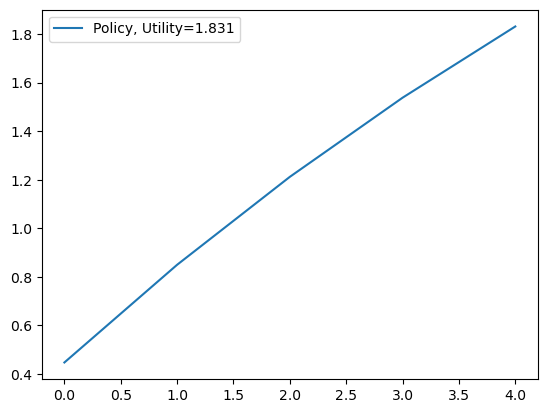

maximum utility: 1.8313843949318778
optimal policy:  [0.2 0.2 0.2 0.2 0.2]


In [12]:
value, policy = find_policy(4, 5, 0.9)
print("maximum utility:", value)
print("optimal policy: ", np.array(policy))
assert np.isclose(value, brute_value(5, 5, 0.9, np.sqrt, 5))    # brute force over every policy
assert np.allclose(policy, 0.2) and np.isclose(value, 1.83, atol=5e-3)

The optimal policy eats one piece per period, as in Figure 18.3, for a value of about 1.8314. A longer horizon with a finer cake and a lower discount factor front-loads the eating: the policy still sums to 1, and its utility is the top-left value $A_{N0}$.

[0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]


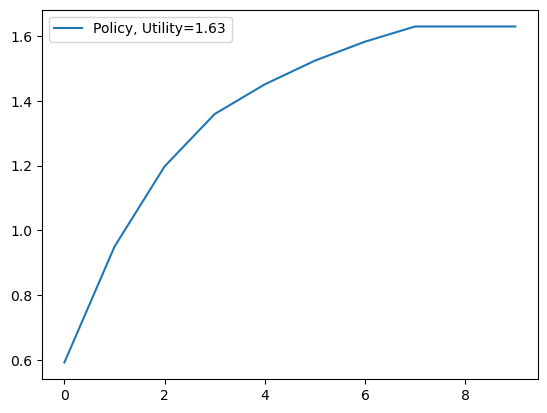

maximum utility: 1.6295301496137955
optimal policy:  [0.35 0.2  0.15 0.1  0.05 0.05 0.05 0.05 0.   0.  ]


In [13]:
value, policy = find_policy(9, 20, 0.8)
print("maximum utility:", value)
print("optimal policy: ", np.array(policy))
assert np.isclose(sum(policy), 1)
assert np.isclose(value, sum(0.8**t * np.sqrt(c) for t, c in enumerate(policy)))

### Summary

The arrays generated in this lab, in the order they were generated:

- **Consumption matrix:** equal to $u(w_i - w_j)$, the utility gained when you start with $i$ pieces and end with $j$ pieces.
- **Value Function Matrix, $A$:** how valuable it is to have $w_i$ pieces at time $j$.
- **Current Value Matrix, $CV^t$:** how valuable each possible decision is at time $t$.
- **Policy Matrix, $P$:** the amount of cake you should eat at time $t$.